# §5 Labels and Bias Audit (Stage S5)

A diabetes label is itself a measurement. Self-report records a past diagnosis and HbA1c records today's
glycaemia under whatever treatment the person receives; neither is "the truth". This section audits the label
layer and two further bias layers before the target is frozen (freeze point 2, `target-freeze`):

| Step | Question | Output |
|---|---|---|
| 1 | How far do self-report and HbA1c agree? | confusion table, κ, PA/NA (`label_audit.csv`) |
| 2 | Does treatment hide diabetes from HbA1c? | treatment masking, A1c-by-medication figure |
| 3 | What does "undiagnosed" mean? | care contact of the undiagnosed |
| 4 | Who is undiagnosed? | risk differences, Korn–Graubard CIs, NCHS flags (`undiagnosed_by_group.csv`) |
| 5 | Does BMI measure adiposity equally for Asian adults? | BMI vs WHtR AUC by race (`bmi_race_roc.csv`) |
| 6 | Whom do the 5,730 represent? | sample vs weighted shares, response, exam selection (`representation.csv`) |
| 7 | Is HbA1c missing at random? | missingness by race, Manski bounds |
| 8 | Decision gate L2 and freeze | C1–C4, `L_comb`, E-SCREEN, 3×3 strata, SL1–SL7 (`governance/label_freeze.md`) |

All findings here were obtained after looking at the data (`prior_exposure = analysis_seen`); they motivate,
but do not count as, pre-registered tests.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

from src import evalkit as E, labels as L, nhanes_io as NIO, survey as S

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = C.RESULTS_DIR / "S5"
OUT.mkdir(parents=True, exist_ok=True)
WT = C.WEIGHT_PHLEB                      # WTPH2YR: cohort analyses (HbA1c sample)
REG_DATE = "2026-10-11"
RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RES: dict = {}                           # -> results/metrics_S5.json
REG: list[dict] = []                     # -> governance/register/S5.csv


def close(value, target, tol, what):
    """Assert a recomputed number against the verified value of process doc §8 / S5 plan."""
    assert abs(value - target) <= tol, f"{what}: got {value:.4f}, expected {target} ± {tol}"


def register(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
             *, hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""):
    REG.append(dict(dr_id=dr_id, stage="S5", date=REG_DATE, type=type_, finding=finding,
                    evidence_ref=evidence_ref, evidence_value=evidence_value, decision=decision,
                    alternatives_rejected=alternatives_rejected, hyp_id=hyp_id, status=status,
                    check_verdict=check_verdict, check_note=check_note, loop_ref=loop_ref,
                    change_request="", commit=""))


def pct(x, nd=1):
    return f"{100 * x:.{nd}f}%"


NCHS_LABEL = {"present": "meets NCHS standard", "review": "exploratory, NCHS statistical review (df < 8)",
              "suppress": "exploratory, does not meet NCHS standard"}


def nchs_label(r):
    """Presentation label from survey.nchs_status (Parker et al. 2017): present / review / suppress."""
    return NCHS_LABEL[r["nchs_status"]]


def kg_text(r):
    flag = nchs_label(r)
    return (f"{pct(r['est'])} (KG {pct(r['kg_low'])}–{pct(r['kg_high'])}, width {r['ci_width']:.2f}; "
            f"n={r['n']}, events={r['n_events']}, df={r['df']}) -> {flag}")


cohort = NIO.build_cohort()
cohort.attrs = {}   # drop the attached sentinel-audit DataFrame (pandas cannot compare DataFrame attrs in concat)
d = L.add_labels(cohort)
assert len(d) == NIO.COHORT_N == 5730
d["race3"] = d["RIDRETH3"].map(RACE)
print(f"cohort: {len(d):,} adults; columns: {d.shape[1]}")

cohort: 5,730 adults; columns: 81


## 1 Three labels and their agreement

**Why.** The research question needs a diabetes label, and the data offer two independent instruments:
`L_self` (DIQ010 = 1, "a doctor told you that you have diabetes") and `L_A1c` (HbA1c ≥ 6.5 %, measured at the
exam). `L_comb` is their union. Before choosing one, we measure how much they agree. Cohen's κ is reported
unweighted and weighted (WTPH2YR, delete-one-PSU jackknife, df = 15). Because κ depends on prevalence, the
positive and negative specific agreements (PA, NA) are reported alongside, as well as the sensitivity and PPV
of self-report against HbA1c.

In [2]:
tab = L.confusion(d)
print("Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts")
print(tab, "\n")
unw = L.agreement(d)
jk_agree = S.jackknife(d, L.agreement_vector, weight=WT)
agree = pd.DataFrame({
    "unweighted": [unw[k] for k in L.AGREEMENT_KEYS],
    "weighted": jk_agree["est"], "w_ci_low": jk_agree["ci_low"], "w_ci_high": jk_agree["ci_high"],
}, index=list(L.AGREEMENT_KEYS)).round(3)
print(agree)

L.check_frozen_counts(d)
close(unw["kappa"], 0.699, 0.0015, "kappa unweighted")
close(unw["pa"], 0.739, 0.0015, "PA")
close(unw["na"], 0.959, 0.0015, "NA")
close(unw["sens"], 0.789, 0.0015, "sensitivity of self-report")
close(unw["ppv"], 0.695, 0.0015, "PPV of self-report")
close(jk_agree["est"][0], 0.709, 0.0015, "kappa weighted")
close(jk_agree["ci_low"][0], 0.665, 0.002, "kappa weighted CI low")
close(jk_agree["ci_high"][0], 0.752, 0.002, "kappa weighted CI high")

n_comb = int(d["L_comb"].sum())
miss_self, miss_a1c = int(tab.loc[0, 1]), int(tab.loc[1, 0])
w_prev = S.weighted_prop(d, "L_comb", weight=WT)
print(f"\nL_comb positives {n_comb} ({pct(n_comb / len(d))} unweighted; weighted {kg_text(w_prev)})")
print(f"L_self misses {miss_self}/{n_comb} = {pct(miss_self / n_comb)} of L_comb positives; "
      f"L_A1c misses {miss_a1c}/{n_comb} = {pct(miss_a1c / n_comb)}")
close(w_prev["est"], 0.140, 0.0015, "weighted L_comb prevalence")

label_audit = pd.DataFrame([
    {"label": lab, "positives": int(d[lab].sum()), "prev_unweighted": d[lab].mean(),
     **{f"w_{k}": v for k, v in S.weighted_prop(d, lab, weight=WT).items()
        if k in ("est", "kg_low", "kg_high", "df")}}
    for lab in L.LABEL_COLS])
label_audit.to_csv(OUT / "label_audit.csv", index=False)
agree.to_csv(OUT / "label_agreement.csv")
RES["labels"] = {
    "confusion": {f"self{i}_a1c{j}": int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)},
    "agreement_unweighted": {k: unw[k] for k in L.AGREEMENT_KEYS},
    "agreement_weighted": {k: {"est": e, "ci_low": lo, "ci_high": hi} for k, e, lo, hi in
                           zip(L.AGREEMENT_KEYS, jk_agree["est"], jk_agree["ci_low"], jk_agree["ci_high"])},
    "positives": {lab: int(d[lab].sum()) for lab in L.LABEL_COLS},
    "L_comb_weighted": {k: w_prev[k] for k in ("est", "ci_low", "ci_high", "kg_low", "kg_high")},
    "L_comb_unweighted": n_comb / len(d),
    "self_missed_share": miss_self / n_comb, "a1c_missed_share": miss_a1c / n_comb,
}
register("DR-S5-02", "label_audit",
         "Self-report and HbA1c are two different instruments with moderate-to-substantial agreement",
         "results/S5/label_agreement.csv; §5.1",
         f"kappa {unw['kappa']:.3f} (weighted {jk_agree['est'][0]:.3f}, CI {jk_agree['ci_low'][0]:.3f}-"
         f"{jk_agree['ci_high'][0]:.3f}); PA {unw['pa']:.3f}; NA {unw['na']:.3f}; sens {unw['sens']:.3f}; PPV {unw['ppv']:.3f}",
         "Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1",
         "Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent)",
         check_note="Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against process doc §8")

Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts
L_A1c      0    1
L_self           
0       4759  152
1        250  569 

       unweighted  weighted  w_ci_low  w_ci_high
kappa       0.699     0.709     0.665      0.752
pa          0.739     0.741     0.701      0.781
na          0.959     0.968     0.962      0.973
sens        0.789     0.784     0.738      0.830
ppv         0.695     0.703     0.652      0.753

L_comb positives 971 (16.9% unweighted; weighted 14.0% (KG 12.5%–15.7%, width 0.03; n=5730, events=971, df=15) -> meets NCHS standard)
L_self misses 152/971 = 15.7% of L_comb positives; L_A1c misses 250/971 = 25.7%


**So what.** The two instruments agree on 93 % of adults, but agreement *on cases* is much weaker: κ = 0.699
(weighted 0.709, CI 0.665–0.752, "substantial" on the Landis–Koch scale only just), PA = 0.739 against
NA = 0.959. Self-report detects 78.9 % of HbA1c-positive adults, and only 69.5 % of self-reported diabetics
are HbA1c-positive on the day of the exam. Each single instrument misses a large part of the union:
`L_self` misses 152/971 = 15.7 % of `L_comb` positives and `L_A1c` misses 250/971 = 25.7 %. The disagreement
is structured, not random noise; steps 2–3 show why.

## 2 Treatment masking

**Why.** 250 self-reported diabetics have HbA1c < 6.5 %. If most of them are treated, a low HbA1c is the
*result* of diagnosis and treatment, and an HbA1c-only label would call well-controlled patients "healthy".
Medication (insulin DIQ050, pills DIQ070) is post-diagnosis information, so it is used here for the audit only,
never as a feature.

self-reported diabetics: 819; HbA1c < 6.5: 250 (30.5%)
  of these on insulin or pills: 165 (66%); untreated: 85, of whom 50 have HbA1c 5.7-6.4
treated self-reported diabetics: 694; HbA1c < 6.5 among them: 23.8%

HbA1c (%) of self-reported diabetics by treatment
                  count  mean   std  min  25%  50%  75%   max
on_med                                                       
insulin or pills  694.0  7.64  1.75  4.1  6.5  7.2  8.3  17.1
no medication     125.0  6.53  1.72  4.7  5.6  6.1  6.7  15.6


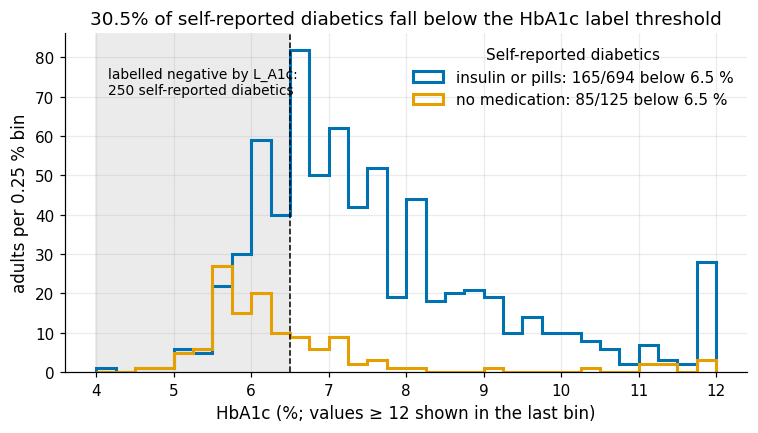

In [3]:
sr = d[d["L_self"] == 1]
ctrl = sr[sr["L_A1c"] == 0]
n_ctrl, n_ctrl_med = len(ctrl), int(ctrl["on_med"].sum())
unmed = ctrl[ctrl["on_med"] == 0]
n_unmed_pre = int(unmed["LBXGH"].between(5.7, 6.49).sum())
on_med = sr[sr["on_med"] == 1]
share_med_below = float((on_med["L_A1c"] == 0).mean())
print(f"self-reported diabetics: {len(sr)}; HbA1c < 6.5: {n_ctrl} ({pct(n_ctrl / len(sr))})")
print(f"  of these on insulin or pills: {n_ctrl_med} ({pct(n_ctrl_med / n_ctrl, 0)}); untreated: {len(unmed)}, "
      f"of whom {n_unmed_pre} have HbA1c 5.7-6.4")
print(f"treated self-reported diabetics: {len(on_med)}; HbA1c < 6.5 among them: {pct(share_med_below)}")
print("\nHbA1c (%) of self-reported diabetics by treatment")
print(sr.groupby(sr["on_med"].map({1: "insulin or pills", 0: "no medication"}))["LBXGH"]
      .describe(percentiles=[.25, .5, .75]).round(2))
assert (n_ctrl, n_ctrl_med, len(unmed), n_unmed_pre, len(on_med)) == (250, 165, 85, 50, 694)
close(n_ctrl / len(sr), 0.305, 0.001, "masking share")
close(share_med_below, 0.238, 0.001, "treated with HbA1c < 6.5")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(4.0, 12.01, 0.25)
ax.axvspan(4.0, C.HBA1C_DIABETES, color="0.92", zorder=0)
for flag, lab, col in [(1, "insulin or pills", plots.PALETTE[4]), (0, "no medication", plots.PALETTE[0])]:
    x = sr.loc[sr["on_med"] == flag, "LBXGH"].clip(upper=11.99)
    below = int((x < C.HBA1C_DIABETES).sum())
    ax.hist(x, bins=bins, histtype="step", lw=2, color=col, label=f"{lab}: {below}/{len(x)} below 6.5 %")
ax.axvline(C.HBA1C_DIABETES, color="k", ls="--", lw=1)
ax.text(4.15, ax.get_ylim()[1] * 0.9, f"labelled negative by L_A1c:\n{n_ctrl} self-reported diabetics", fontsize=9, va="top")
ax.set(xlabel="HbA1c (%; values ≥ 12 shown in the last bin)", ylabel="adults per 0.25 % bin",
       title=f"{pct(n_ctrl / len(sr))} of self-reported diabetics fall below the HbA1c label threshold")
ax.legend(loc="upper right", title="Self-reported diabetics")
plots.savefig(fig, "S5_a1c_by_medication",
              caption=f"HbA1c distribution of the {len(sr)} self-reported diabetics by current insulin/pill use. "
                      f"{n_ctrl} ({pct(n_ctrl / len(sr))}) are below 6.5 %, {n_ctrl_med} of them treated.")
plt.show()

RES["masking"] = {"self_reported": len(sr), "below_6_5": n_ctrl, "below_6_5_share": n_ctrl / len(sr),
                  "below_6_5_on_med": n_ctrl_med, "below_6_5_untreated": len(unmed),
                  "untreated_5_7_to_6_4": n_unmed_pre, "treated": len(on_med),
                  "treated_below_6_5_share": share_med_below}
register("DR-S5-03", "label_bias",
         "Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives",
         "figures/S5_a1c_by_medication.png; §5.2",
         f"{n_ctrl}/{len(sr)} ({pct(n_ctrl / len(sr))}) self-reported diabetics have HbA1c<6.5; {n_ctrl_med} of them on medication; "
         f"{pct(share_med_below)} of treated patients below 6.5",
         "Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)",
         "HbA1c-only target; medication as a feature (leakage by the availability rule)")

**So what.** 250 of 819 self-reported diabetics (30.5 %) are below the HbA1c threshold, and 165 of these
(66 %) take insulin or pills; among all 694 treated patients 23.8 % are "controlled". The remaining 85 are
untreated, 50 of them in the prediabetes range (5.7–6.4 %), consistent with lifestyle-controlled or
early disease. An HbA1c-only label would therefore count successful treatment as absence of disease: this is
the *D_controlled* column of the 3×3 label matrix in S8.

## 3 What "undiagnosed" means

**Why.** The 152 adults with HbA1c ≥ 6.5 % who do not report diabetes are the population the screening use case
is about (E-SCREEN). "Undiagnosed" is easily read as "never saw a doctor". DIQ010 = 3 (borderline), DIQ180
(blood test for high blood sugar in the past three years) and DIQ160 (told prediabetes) show whether they
had contact with the system. Counts are unweighted; shares among the undiagnosed are also weighted with
Korn–Graubard intervals.

In [4]:
bl = d["DIQ010"].eq(3)
no = d["DIQ010"].eq(2)
p_bl, p_no = d.loc[bl, "L_A1c"].mean(), d.loc[no, "L_A1c"].mean()
print(f"DIQ010 = 3 (borderline): {int(bl.sum())}; HbA1c >= 6.5: {int(d.loc[bl, 'L_A1c'].sum())} ({pct(p_bl)}) "
      f"vs DIQ010 = 2: {pct(p_no)}")
und_mask = (d["stratum_3x3"] == "Undiagnosed").to_numpy()
und = d[und_mask]
care = {
    "told borderline (DIQ010=3)": und["DIQ010"].eq(3),
    "blood test past 3 years (DIQ180=1)": und["DIQ180"].eq(1),
    "told prediabetes (DIQ160=1)": und["DIQ160"].eq(1),
}
rows = []
for name, s in care.items():
    y = np.where(und_mask, d.index.isin(s[s].index), np.nan)
    w = S.weighted_prop(d, y.astype(float), weight=WT, domain=und_mask)
    rows.append({"contact": name, "n": int(s.sum()), "of": len(und), "share": s.sum() / len(und),
                 "w_est": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"],
                 "flags": ";".join(w["nchs_flags"]), "nchs": nchs_label(w)})
care_tab = pd.DataFrame(rows)
print(care_tab.round(3).to_string(index=False))
print(f"DIQ180 missing among undiagnosed: {int(und['DIQ180'].isna().sum())}; DIQ160 missing: {int(und['DIQ160'].isna().sum())} "
      "(borderline respondents skip DIQ160)")
assert int(bl.sum()) == 213 and int(d.loc[bl, "L_A1c"].sum()) == 36 and len(und) == 152
assert care_tab["n"].tolist() == [36, 104, 48]
close(p_bl, 0.169, 0.001, "borderline A1c+ share")
close(p_no, 0.025, 0.001, "DIQ010=2 A1c+ share")
care_tab.to_csv(OUT / "undiagnosed_care_contact.csv", index=False)
RES["undiagnosed_meaning"] = {"borderline_n": int(bl.sum()), "borderline_a1c_pos": int(d.loc[bl, "L_A1c"].sum()),
                              "borderline_a1c_share": p_bl, "no_a1c_share": p_no, "undiagnosed": len(und),
                              "contact": care_tab.set_index("contact")[["n", "share", "w_est", "kg_low", "kg_high"]].to_dict("index")}
register("DR-S5-04", "label_semantics",
         "Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",
         "results/S5/undiagnosed_care_contact.csv; §5.3",
         f"of 152 undiagnosed: 36 told borderline (24%), 104 blood-tested in past 3 y (68%), 48 told prediabetes",
         "Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged",
         "Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature")

DIQ010 = 3 (borderline): 213; HbA1c >= 6.5: 36 (16.9%) vs DIQ010 = 2: 2.5%
                           contact   n  of  share  w_est  kg_low  kg_high  df flags                nchs
        told borderline (DIQ010=3)  36 152  0.237  0.235   0.165    0.318  14       meets NCHS standard
blood test past 3 years (DIQ180=1) 104 152  0.684  0.625   0.535    0.709  14       meets NCHS standard
       told prediabetes (DIQ160=1)  48 152  0.316  0.306   0.227    0.395  14       meets NCHS standard
DIQ180 missing among undiagnosed: 2; DIQ160 missing: 37 (borderline respondents skip DIQ160)


**So what.** Borderline respondents are almost seven times as likely to be HbA1c-positive as those answering
"no" (16.9 % vs 2.5 %). Of the 152 undiagnosed, 104 (68 %) had a blood-sugar test in the past three years,
36 (24 %) were told they were borderline and 48 were told they had prediabetes. "Undiagnosed" is therefore
mostly a diagnosis and communication gap, not a lack of any contact. This is also why DIQ160 and DIQ180 are
excluded as features: they record the result of a glucose test, which the screening use case comes before.

## 4 Who is undiagnosed

**Why.** If the undiagnosed share differs by insurance, access or race, then `L_self` is a biased label
and a model trained on it inherits the bias. The domain is all adults with HbA1c ≥ 6.5 % (n = 721) and the
outcome is "not self-reported". Following NCHS presentation standards, proportions get Korn–Graubard intervals
with the design-based effective sample size and the NCHS domain df (PSUs containing the domain minus strata
containing it). An estimate with n or effective n < 30, an absolute CI width ≥ 0.30, or a CI width > 0.05 with
a relative width > 130 % is labelled *exploratory, does not meet NCHS standard*; df < 8 additionally triggers
NCHS statistical review.
The headline quantity is the risk difference (WTPH2YR, delete-one-PSU jackknife, df = domain df) rather than a
small-cell proportion.

In [5]:
d["undx"] = 1.0 - d["L_self"]
d["uninsured"] = np.select([d["HIQ011"].eq(2), d["HIQ011"].eq(1)], [1.0, 0.0], np.nan)
d["no_usual_place"] = np.select([d["HUQ030"].eq(2), d["HUQ030"].isin([1, 3])], [1.0, 0.0], np.nan)
a1c_dom = d["L_A1c"].eq(1).to_numpy()


def risk_difference(df, y, ga, gb, weight=WT):
    """Weighted risk difference p(a) - p(b) with JK CI (df = NCHS domain df of a or b)."""
    yv = df[y].to_numpy(float)
    ok = ~np.isnan(yv)
    a, b = np.asarray(ga) & ok, np.asarray(gb) & ok
    y0 = np.nan_to_num(yv)

    def f(_d, w):
        return np.dot(w * a, y0) / np.sum(w * a) - np.dot(w * b, y0) / np.sum(w * b)
    return S.jackknife(df, f, weight=weight, df_override=S.domain_df(df, a | b))


contrasts = [  # (name, column, level a, level b, label a, label b)
    ("uninsured - insured", "uninsured", 1.0, 0.0, "uninsured", "insured"),
    ("no usual place - usual place", "no_usual_place", 1.0, 0.0, "no usual place", "usual place"),
    ("NH Asian - NH White", "RIDRETH3", 6, 3, "NH Asian", "NH White"),
]
prop_rows, rd_rows = [], []
for name, col, a, b, la, lb in contrasts:
    for lev, lab in [(a, la), (b, lb)]:
        r = S.weighted_prop(d, "undx", weight=WT, domain=a1c_dom & d[col].eq(lev).to_numpy())
        prop_rows.append({"group": lab, "contrast": name, **{k: r[k] for k in
                          ("n", "n_events", "est", "kg_low", "kg_high", "ci_width", "n_eff", "df")},
                          "nchs": nchs_label(r), "nchs_status": r["nchs_status"], "flags": ";".join(r["nchs_flags"])})
    rd = risk_difference(d, "undx", a1c_dom & d[col].eq(a).to_numpy(), a1c_dom & d[col].eq(b).to_numpy())
    rd_rows.append({"contrast": name, "rd_pp": 100 * rd["est"], "ci_low_pp": 100 * rd["ci_low"],
                    "ci_high_pp": 100 * rd["ci_high"], "df": rd["df"]})
props = pd.DataFrame(prop_rows).drop_duplicates("group")
rds = pd.DataFrame(rd_rows)
print("Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)")
print(props.drop(columns="flags").round(3).to_string(index=False))
print("\nRisk differences (percentage points, JK CI)")
print(rds.round(1).to_string(index=False))

P = props.set_index("group")
close(P.loc["uninsured", "est"], 0.430, 0.0015, "uninsured share"); assert P.loc["uninsured", "n"] == 49
close(P.loc["uninsured", "kg_low"], 0.242, 0.002, "uninsured KG low"); close(P.loc["uninsured", "kg_high"], 0.635, 0.002, "uninsured KG high")
assert P.loc["uninsured", "df"] == 9 and P.loc["no usual place", "df"] == 9
close(P.loc["insured", "est"], 0.199, 0.0015, "insured share")
close(P.loc["no usual place", "est"], 0.403, 0.0015, "no usual place share"); assert P.loc["no usual place", "n"] == 41
close(P.loc["NH Asian", "est"], 0.362, 0.0015, "Asian share"); assert P.loc["NH Asian", "n"] == 40 and P.loc["NH Asian", "df"] == 4
close(P.loc["NH Asian", "kg_low"], 0.131, 0.002, "Asian KG low"); close(P.loc["NH Asian", "kg_high"], 0.652, 0.002, "Asian KG high")
for g in ("uninsured", "no usual place", "NH Asian"):
    assert P.loc[g, "ci_width"] >= C.NCHS_CI_WIDTH_MAX and P.loc[g, "nchs_status"] == "suppress"
assert P.loc["insured", "nchs"] == "meets NCHS standard"
RD = rds.set_index("contrast")
for name, (e, lo, hi) in {"uninsured - insured": (23.2, 6.2, 40.1), "no usual place - usual place": (20.0, -1.6, 41.6),
                          "NH Asian - NH White": (15.6, -5.7, 36.9)}.items():
    close(RD.loc[name, "rd_pp"], e, 0.15, name); close(RD.loc[name, "ci_low_pp"], lo, 0.15, name + " low")
    close(RD.loc[name, "ci_high_pp"], hi, 0.15, name + " high")

Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)
         group                     contrast   n  n_events   est  kg_low  kg_high  ci_width   n_eff  df                                     nchs nchs_status
     uninsured          uninsured - insured  49        18 0.430   0.242    0.635     0.393  33.776   9 exploratory, does not meet NCHS standard    suppress
       insured          uninsured - insured 670       133 0.199   0.157    0.246     0.088 392.084  15                      meets NCHS standard     present
no usual place no usual place - usual place  41        17 0.403   0.200    0.633     0.433  26.951   9 exploratory, does not meet NCHS standard    suppress
   usual place no usual place - usual place 680       135 0.203   0.158    0.256     0.098 327.872  15                      meets NCHS standard     present
      NH Asian          NH Asian - NH White  40        12 0.362   0.131    0.652     0.520  26.575   4 exploratory, does not meet NCHS standard    suppress
  

**Adjusted model.** Insurance, a usual place of care and race are correlated (and all correlate with age), so
each contrast is also estimated in a logistic model of "undiagnosed" among the HbA1c-positive adults,
adjusted for age, sex and BMI. The primary fit is unweighted (model-based CI), matching the S5 plan; a
WTPH2YR-weighted fit with jackknife CIs is shown as a design-based sensitivity check.

In [6]:
FORM = "undx ~ no_usual_place + uninsured + race_cat + age10 + male + BMXBMI"   # reference race: NH White
RACE_LEVELS = ["NH White", *[r for r in RACE.values() if r != "NH White"]]
lg = d[a1c_dom].assign(age10=lambda x: x["RIDAGEYR"] / 10, male=lambda x: x["RIAGENDR"].eq(1).astype(float),
                       race_cat=lambda x: pd.Categorical(x["race3"], categories=RACE_LEVELS))
lg = lg.dropna(subset=["undx", "no_usual_place", "uninsured", "race3", "age10", "BMXBMI"])
fit = smf.logit(FORM, data=lg).fit(disp=0)
KEYS = {"no_usual_place": "no usual place", "uninsured": "uninsured", "race_cat[T.NH Asian]": "NH Asian"}
ci = fit.conf_int()
logit_tab = pd.DataFrame({"term": list(KEYS.values()), "OR": np.exp(fit.params[list(KEYS)]).values,
                          "ci_low": np.exp(ci.loc[list(KEYS), 0]).values, "ci_high": np.exp(ci.loc[list(KEYS), 1]).values})


def wlogit_logor(df, w):
    m = w > 0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f = smf.glm(FORM, data=df[m], family=sm.families.Binomial(), freq_weights=w[m] / w[m].mean()).fit()
    return f.params[list(KEYS)].to_numpy()


jk_lg = S.jackknife(lg, wlogit_logor, weight=WT)
logit_tab["OR_w"] = np.exp(jk_lg["est"])
logit_tab["w_ci_low"] = np.exp(jk_lg["ci_low"])
logit_tab["w_ci_high"] = np.exp(jk_lg["ci_high"])
n_dom = int(a1c_dom.sum())
print(f"complete cases n = {len(lg)} of {n_dom} (dropped: {int(d.loc[a1c_dom, 'BMXBMI'].isna().sum())} without BMI, "
      f"{int(d.loc[a1c_dom, 'uninsured'].isna().sum())} with unknown insurance); undiagnosed events = {int(lg['undx'].sum())}")
print(logit_tab.round(2).to_string(index=False))
LT = logit_tab.set_index("term")
# S5 plan: n=706, OR 2.84 / 1.80 / 1.69. Our complete-case model (unknown insurance excluded, not coded insured)
# has n=704; the ORs agree within sampling noise and the inferential pattern is identical (asserted).
assert len(lg) == 704
close(LT.loc["no usual place", "OR"], 2.84, 0.30, "OR no usual place")
close(LT.loc["uninsured", "OR"], 1.80, 0.10, "OR uninsured")
close(LT.loc["NH Asian", "OR"], 1.69, 0.10, "OR Asian")
assert LT.loc["no usual place", "ci_low"] > 1 and LT.loc["uninsured", "ci_low"] < 1 < LT.loc["uninsured", "ci_high"]
assert LT.loc["NH Asian", "ci_low"] < 1 < LT.loc["NH Asian", "ci_high"]

complete cases n = 704 of 721 (dropped: 15 without BMI, 2 with unknown insurance); undiagnosed events = 149
          term   OR  ci_low  ci_high  OR_w  w_ci_low  w_ci_high
no usual place 2.59    1.25     5.38  2.15      0.91       5.11
     uninsured 1.84    0.92     3.64  2.24      1.08       4.61
      NH Asian 1.68    0.76     3.69  2.23      0.84       5.94


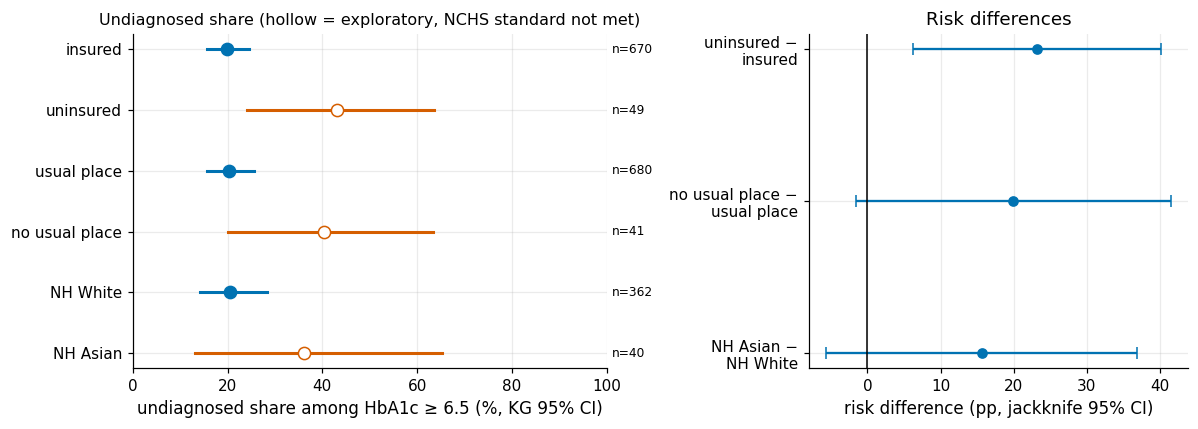

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["insured", "uninsured", "usual place", "no usual place", "NH White", "NH Asian"]
pp = P.loc[order]
yy = np.arange(len(order))[::-1]
for yi, (g, r) in zip(yy, pp.iterrows()):
    expl = r["nchs"].startswith("exploratory")
    col = plots.PALETTE[5] if expl else plots.PALETTE[4]
    ax1.plot([r["kg_low"] * 100, r["kg_high"] * 100], [yi, yi], color=col, lw=2)
    ax1.plot(r["est"] * 100, yi, "o", color=col, mfc="white" if expl else col, ms=8)
    ax1.text(101, yi, f"n={int(r['n'])}", va="center", fontsize=8)
ax1.set_yticks(yy, order)
ax1.set(xlim=(0, 100), xlabel="undiagnosed share among HbA1c ≥ 6.5 (%, KG 95% CI)",
        title="Undiagnosed share (hollow = exploratory, NCHS standard not met)")
ax1.title.set_fontsize(10.5)
yr = np.arange(len(rds))[::-1]
ax2.errorbar(rds["rd_pp"], yr, xerr=[rds["rd_pp"] - rds["ci_low_pp"], rds["ci_high_pp"] - rds["rd_pp"]],
             fmt="o", color=plots.PALETTE[4], capsize=4)
ax2.axvline(0, color="k", lw=1)
ax2.set_yticks(yr, [c.replace(" - ", " −\n") for c in rds["contrast"]])
ax2.set(xlabel="risk difference (pp, jackknife 95% CI)", title="Risk differences")
fig.tight_layout()
plots.savefig(fig, "S5_undiagnosed_inequality",
              caption="Share of HbA1c-positive adults who do not report diabetes (WTPH2YR, Korn-Graubard CI) and risk "
                      "differences with delete-one-PSU jackknife CI. Hollow markers: fails the NCHS presentation standard (exploratory).")
plt.show()

props.to_csv(OUT / "undiagnosed_by_group.csv", index=False)
rds.to_csv(OUT / "undiagnosed_risk_differences.csv", index=False)
logit_tab.to_csv(OUT / "undiagnosed_logit.csv", index=False)
RES["undiagnosed_inequality"] = {
    "proportions": props.set_index("group").drop(columns=["contrast"]).to_dict("index"),
    "risk_differences_pp": rds.set_index("contrast").to_dict("index"),
    "logit": {"n": len(lg), "events": int(lg["undx"].sum()), "formula": FORM,
              "or": logit_tab.set_index("term").to_dict("index")},
}
register("DR-S5-05", "label_bias",
         "Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards",
         "results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png",
         f"RD uninsured-insured {RD.loc['uninsured - insured', 'rd_pp']:.1f}pp ({RD.loc['uninsured - insured', 'ci_low_pp']:.1f}, "
         f"{RD.loc['uninsured - insured', 'ci_high_pp']:.1f}); uninsured share 43.0% KG width {P.loc['uninsured', 'ci_width']:.2f}; "
         f"adjusted OR no usual place {LT.loc['no usual place', 'OR']:.2f}",
         "Headline = risk difference with JK CI; proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access",
         "Report small-cell proportions as headline; drop small groups; put insurance into the model")

**So what.** Among HbA1c-positive adults, 43.0 % of the uninsured but 19.9 % of the insured do not know their
diagnosis: a risk difference of +23.2 pp (6.2, 40.1) whose interval excludes zero. Without a usual place of care
the difference is +19.9 pp (−1.6, 41.5) and for NH Asian versus NH White adults +15.6 pp (−5.7, 36.9); both
intervals include zero. All three group proportions have KG intervals wider than 0.30 (uninsured 24.2–63.5 %,
df = 9; Asian 13.1–65.2 %, n = 40, df = 4), so they are *exploratory and do not meet the NCHS standard*; they
are not headlines. Adjusted for age,
sex, BMI and each other (complete cases, n = 704), lacking a usual place of care remains associated with being
undiagnosed (OR 2.6, CI excludes 1), the insurance and Asian ORs are imprecise (CIs include 1), and the design-based weighted fit
gives wider intervals. Consequence for the label: `L_self` systematically under-counts disease in groups with
poorer access, which is why the target is the union `L_comb` and why S8 compares training labels.

## 5 BMI as a biased measurement of adiposity in Asian adults

**Why.** BMI is the main adiposity feature of any non-laboratory screening model. Asian adults develop
diabetes at lower BMI (Araneta et al. 2015; WHO Expert Consultation 2004), so the same BMI value may carry
different information by race: a *feature-level* measurement bias. We compare NH Asian with NH White adults on
(a) the BMI of diabetics, (b) `L_comb` prevalence by BMI band, (c) the discrimination (single-feature ROC-AUC)
of BMI, waist circumference and waist-to-height ratio (WHtR), with a paired bootstrap of the WHtR − BMI gain,
and (d) the sensitivity of the BMI ≥ 25 and ≥ 23 screening cut-offs. These are unweighted *measurement*
properties of the sample; the White group is the control comparison.

In [8]:
grp = {"NH Asian": 6, "NH White": 3}
bmi_dm = []
for g, code in grp.items():
    dm = d[(d["RIDRETH3"] == code) & (d["L_comb"] == 1) & d["BMXBMI"].notna()]
    k = int((dm["BMXBMI"] < 25).sum())
    w = S.weighted_prop(d, (d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna()), weight=WT,
                        domain=((d["RIDRETH3"] == code) & (d["L_comb"] == 1)).to_numpy())
    bmi_dm.append({"group": g, "bmi_lt25": k, "diabetics_with_bmi": len(dm), "share": k / len(dm),
                   "median_bmi": dm["BMXBMI"].median(), "w_share": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"]})
bmi_dm = pd.DataFrame(bmi_dm).set_index("group")
print("BMI < 25 among L_comb diabetics (denominator excludes missing BMI)")
print(bmi_dm.round(3))
assert (bmi_dm.loc["NH Asian", "bmi_lt25"], bmi_dm.loc["NH Asian", "diabetics_with_bmi"]) == (24, 47)
close(bmi_dm.loc["NH Asian", "share"], 0.511, 0.001, "Asian BMI<25"); close(bmi_dm.loc["NH White", "share"], 0.072, 0.001, "White BMI<25")

BANDS = [0, 23, 25, 30, 200]
BLAB = ["<23", "23–24.9", "25–29.9", "≥30"]
d["bmi_band"] = pd.cut(d["BMXBMI"], BANDS, right=False, labels=BLAB)
band_rows = []
for g, code in grp.items():
    for b in BLAB:
        m = ((d["RIDRETH3"] == code) & (d["bmi_band"] == b)).to_numpy()
        w = S.weighted_prop(d, "L_comb", weight=WT, domain=m)
        band_rows.append({"group": g, "bmi_band": b, "n": int(m.sum()), "cases": int(d.loc[m, "L_comb"].sum()),
                          "prev": d.loc[m, "L_comb"].mean(), "w_prev": w["est"], "kg_low": w["kg_low"],
                          "kg_high": w["kg_high"], "ci_width": w["ci_width"], "df": w["df"],
                          "nchs_status": w["nchs_status"], "flags": ";".join(w["nchs_flags"])})
bands = pd.DataFrame(band_rows)
print("\nL_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)")
print(bands.round(3).to_string(index=False))
B_ = bands.set_index(["group", "bmi_band"])
n_flag_asian = int((bands.loc[bands["group"] == "NH Asian", "nchs_status"] != "present").sum())
print(f"NH Asian BMI bands failing the NCHS presentation standard: {n_flag_asian} of {len(BLAB)}")
assert n_flag_asian >= 3
close(B_.loc[("NH Asian", "<23"), "prev"], 0.121, 0.001, "Asian <23"); close(B_.loc[("NH White", "<23"), "prev"], 0.043, 0.001, "White <23")
close(B_.loc[("NH Asian", "23–24.9"), "prev"], 0.175, 0.001, "Asian 23-25"); close(B_.loc[("NH White", "23–24.9"), "prev"], 0.033, 0.001, "White 23-25")
close(B_.loc[("NH Asian", "<23"), "w_prev"], 0.078, 0.001, "Asian <23 weighted"); close(B_.loc[("NH Asian", "23–24.9"), "w_prev"], 0.140, 0.001, "Asian 23-25 weighted")

BMI < 25 among L_comb diabetics (denominator excludes missing BMI)
          bmi_lt25  diabetics_with_bmi  share  median_bmi  w_share  kg_low  kg_high
group                                                                              
NH Asian        24                  47  0.511        24.9    0.501   0.255    0.747
NH White        35                 488  0.072        32.7    0.067   0.045    0.096

L_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)
   group bmi_band    n  cases  prev  w_prev  kg_low  kg_high  ci_width  df nchs_status                  flags
NH Asian      <23  107     13 0.121   0.078   0.028    0.167     0.139   9    suppress      rel_ci_width>130%
NH Asian  23–24.9   63     11 0.175   0.140   0.049    0.291     0.242   5    suppress rel_ci_width>130%;df<8
NH Asian  25–29.9   96     11 0.115   0.053   0.014    0.133     0.119   8    suppress      rel_ci_width>130%
NH Asian      ≥30   44     12 0.273   0.284   0.104    0.536     0.431   5    suppress    

In [9]:
FEATS = {"BMI": "BMXBMI", "waist": "BMXWAIST", "WHtR": "whtr"}
B = C.N_BOOT
rng = np.random.default_rng(E.derive_seed(C.SEED_MASTER, "S5", "auc_bootstrap"))


def auc_set(g):
    out = {}
    for f, col in FEATS.items():
        ok = g[col].notna()
        out[f] = roc_auc_score(g.loc[ok, "L_comb"], g.loc[ok, col])
    both = g["BMXBMI"].notna() & g["whtr"].notna()
    out["gain"] = (roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "whtr"])
                   - roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "BMXBMI"]))
    return out


roc_rows, boot_store = [], {}
for g, code in grp.items():
    sub = d.loc[d["RIDRETH3"] == code, ["L_comb", *FEATS.values()]].reset_index(drop=True)
    est = auc_set(sub)
    pos, neg = np.flatnonzero(sub["L_comb"] == 1), np.flatnonzero(sub["L_comb"] == 0)
    reps = pd.DataFrame([auc_set(sub.iloc[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])])
                         for _ in range(B)])
    boot_store[g] = reps
    for k in [*FEATS, "gain"]:
        roc_rows.append({"group": g, "measure": k if k != "gain" else "WHtR − BMI (paired)",
                         "n": int(sub[FEATS[k]].notna().sum()) if k in FEATS else int((sub["BMXBMI"].notna() & sub["whtr"].notna()).sum()),
                         "auc": est[k], "ci_low": reps[k].quantile(0.025), "ci_high": reps[k].quantile(0.975)})
roc = pd.DataFrame(roc_rows)
gain_diff = boot_store["NH Asian"]["gain"] - boot_store["NH White"]["gain"]
print(f"Single-feature ROC-AUC for L_comb (stratified bootstrap, B = {B})")
print(roc.round(3).to_string(index=False))
print(f"Asian minus White WHtR gain: {roc.iloc[3]['auc'] - roc.iloc[7]['auc']:+.3f} "
      f"(bootstrap 95% CI {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f})")
RO = roc.set_index(["group", "measure"])
assert gain_diff.quantile(.025) > 0, "Asian WHtR gain no longer exceeds the White gain"
close(RO.loc[("NH Asian", "BMI"), "auc"], 0.573, 0.001, "Asian BMI AUC")
close(RO.loc[("NH Asian", "waist"), "auc"], 0.697, 0.001, "Asian waist AUC")
close(RO.loc[("NH Asian", "WHtR"), "auc"], 0.714, 0.001, "Asian WHtR AUC")
close(RO.loc[("NH White", "BMI"), "auc"], 0.701, 0.001, "White BMI AUC")
close(RO.loc[("NH White", "WHtR"), "auc"], 0.749, 0.001, "White WHtR AUC")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"], 0.136, 0.002, "Asian gain")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"], 0.048, 0.002, "White gain")
tol_ci = 0.01 if C.IS_FINAL else 0.03   # bootstrap CI bounds: tighter check in FINAL (B=1000)
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_low"], 0.092, tol_ci, "Asian gain CI low")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_high"], 0.183, tol_ci, "Asian gain CI high")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_low"], 0.039, tol_ci, "White gain CI low")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_high"], 0.059, tol_ci, "White gain CI high")

Single-feature ROC-AUC for L_comb (stratified bootstrap, B = 100)
   group             measure    n   auc  ci_low  ci_high
NH Asian                 BMI  310 0.573   0.489    0.655
NH Asian               waist  296 0.697   0.614    0.762
NH Asian                WHtR  296 0.714   0.646    0.776
NH Asian WHtR − BMI (paired)  296 0.137   0.097    0.184
NH White                 BMI 3370 0.701   0.676    0.723
NH White               waist 3274 0.751   0.729    0.775
NH White                WHtR 3268 0.749   0.728    0.772
NH White WHtR − BMI (paired) 3264 0.049   0.038    0.058
Asian minus White WHtR gain: +0.088 (bootstrap 95% CI +0.045, +0.138)


In [10]:
cut_rows = []
for g, code in grp.items():
    sub = d[(d["RIDRETH3"] == code) & d["BMXBMI"].notna()]
    y = sub["L_comb"].eq(1)
    for cut in (25, 23):
        flag = sub["BMXBMI"] >= cut
        cut_rows.append({"group": g, "rule": f"BMI ≥ {cut}", "sensitivity": flag[y].mean(),
                         "specificity": (~flag[~y]).mean(), "flagged_share": flag.mean(), "cases": int(y.sum())})
cuts = pd.DataFrame(cut_rows)
print(cuts.round(3).to_string(index=False))
CU = cuts.set_index(["group", "rule"])
close(CU.loc[("NH Asian", "BMI ≥ 25"), "sensitivity"], 0.489, 0.001, "Asian sens BMI>=25")
close(CU.loc[("NH White", "BMI ≥ 25"), "sensitivity"], 0.928, 0.001, "White sens BMI>=25")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "sensitivity"], 0.723, 0.001, "Asian sens BMI>=23")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "specificity"], 0.357, 0.001, "Asian spec BMI>=23")

   group     rule  sensitivity  specificity  flagged_share  cases
NH Asian BMI ≥ 25        0.489        0.555          0.452     47
NH Asian BMI ≥ 23        0.723        0.357          0.655     47
NH White BMI ≥ 25        0.928        0.303          0.731    488
NH White BMI ≥ 23        0.957        0.161          0.856    488


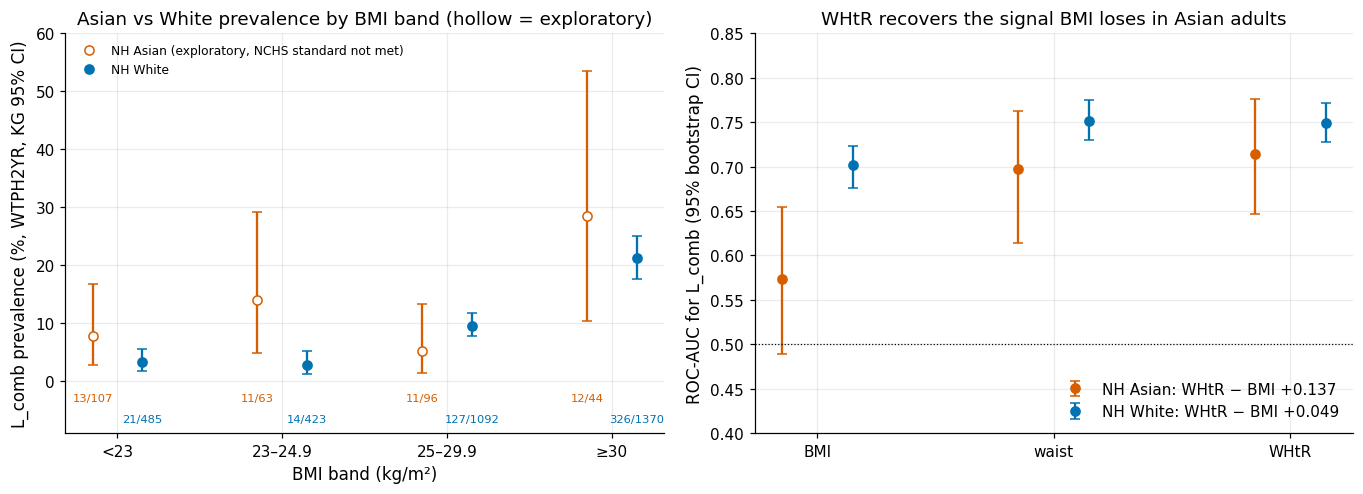

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
xb = np.arange(len(BLAB))
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    sb = bands[bands["group"] == g]
    off = (i - 0.5) * 0.3
    ax1.errorbar(xb + off, sb["w_prev"] * 100, yerr=[(sb["w_prev"] - sb["kg_low"]) * 100, (sb["kg_high"] - sb["w_prev"]) * 100],
                 fmt="none", ecolor=col, capsize=3)
    ok = (sb["nchs_status"] == "present").to_numpy()
    ax1.plot((xb + off)[ok], sb["w_prev"].to_numpy()[ok] * 100, "o", color=col, label=g if ok.any() else None)
    ax1.plot((xb + off)[~ok], sb["w_prev"].to_numpy()[~ok] * 100, "o", color=col, mfc="white",
             label=f"{g} (exploratory, NCHS standard not met)" if (~ok).any() else None)
    for x_, (_, r) in zip(xb + off, sb.iterrows()):
        ax1.text(x_, -3.5 - 3.5 * i, f"{r['cases']}/{r['n']}", ha="center", fontsize=7.5, color=col)
ax1.set_xticks(xb, BLAB)
ax1.set(xlabel="BMI band (kg/m²)", ylabel="L_comb prevalence (%, WTPH2YR, KG 95% CI)", ylim=(-9, 60),
        title="Asian vs White prevalence by BMI band (hollow = exploratory)")
ax1.legend(loc="upper left", fontsize=8)
meas = ["BMI", "waist", "WHtR"]
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    rr = RO.loc[g].loc[meas]
    off = (i - 0.5) * 0.3
    ax2.errorbar(np.arange(3) + off, rr["auc"], yerr=[rr["auc"] - rr["ci_low"], rr["ci_high"] - rr["auc"]],
                 fmt="o", color=col, capsize=3,
                 label=f"{g}: WHtR − BMI {RO.loc[(g, 'WHtR − BMI (paired)'), 'auc']:+.3f}")
ax2.axhline(0.5, color="k", lw=0.8, ls=":")
ax2.set_xticks(range(3), meas)
ax2.set(ylabel="ROC-AUC for L_comb (95% bootstrap CI)", ylim=(0.4, 0.85),
        title="WHtR recovers the signal BMI loses in Asian adults")
ax2.legend(loc="lower right")
fig.tight_layout()
plots.savefig(fig, "S5_asian_bmi_whtr",
              caption="Left: L_comb prevalence by BMI band, NH Asian vs NH White (WTPH2YR, Korn-Graubard CI; labels = cases/n; "
                      "hollow markers fail the NCHS presentation standard and are exploratory). "
                      "Right: single-feature ROC-AUC of BMI, waist and WHtR with stratified bootstrap CI; legend = paired WHtR - BMI gain.")
plt.show()

roc.to_csv(OUT / "bmi_race_roc.csv", index=False)
bands.to_csv(OUT / "bmi_band_prevalence.csv", index=False)
cuts.to_csv(OUT / "bmi_cutoff_sensitivity.csv", index=False)
RES["asian_bmi"] = {
    "bmi_lt25_among_diabetics": bmi_dm.to_dict("index"),
    "band_prevalence": {f"{g}|{b}": v for (g, b), v in B_[["n", "cases", "prev", "w_prev", "kg_low", "kg_high"]].to_dict("index").items()},
    "auc": {f"{g}|{m}": v for (g, m), v in RO[["n", "auc", "ci_low", "ci_high"]].to_dict("index").items()},
    "gain_difference_asian_minus_white": {"est": float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"]),
                                          "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975)},
    "cutoffs": {f"{g}|{r}": v for (g, r), v in CU.to_dict("index").items()},
    "n_boot": B,
}
register("DR-S5-06", "measurement_bias",
         "BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination",
         "results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png",
         f"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White {pct(bmi_dm.loc['NH White', 'share'])}; AUC gain WHtR-BMI Asian "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'auc']:+.3f} ({RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_low']:.3f}, "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_high']:.3f}) vs White {RO.loc[('NH White', 'WHtR − BMI (paired)'), 'auc']:+.3f}",
         "Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds",
         "Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (undetectable, S4)",
         hyp_id="H-P14")

**So what.** Half of the Asian diabetics (24/47, 51.1 %) have a "normal" BMI below 25, against 7.2 % of White
diabetics. In the BMI bands below 25 the sample prevalence among Asian adults is 12.1 % (< 23) and 17.5 %
(23–24.9) against 4.3 % and 3.3 % among White adults (weighted, as in the figure: 7.8 % vs 3.3 % and 14.0 % vs
2.8 %). These band estimates rest on 44–107 Asian adults each and all four fail the NCHS presentation standard
(relative CI width > 130 % or absolute width ≥ 0.30, two with df < 8), so they are exploratory: they are
compatible with diabetes occurring at lower BMI in Asian adults but do not establish band-specific rates. The
robust part of the evidence is the case-based BMI share above and the discrimination analysis below: BMI barely discriminates in Asian adults
(AUC 0.573), while waist (0.697) and WHtR (0.714) do. The paired WHtR − BMI gain is +0.137 in Asian adults
(bootstrap CI roughly 0.09–0.18) against +0.049 in White adults (CI roughly 0.04–0.06); the Asian-minus-White
difference in gain, +0.088, has a bootstrap CI that excludes zero. (Exact bounds are printed above; they move
slightly between FAST, B = 100, and FINAL, B = 1,000.) A BMI ≥ 25 rule finds only 48.9 % of Asian cases
(White 92.8 %); lowering the cut-off to 23 (the ADA recommendation for Asian Americans) raises sensitivity to
72.3 % at a specificity of only 35.7 %. The direction agrees with Araneta et al. (2015). With 40–50 Asian cases
this is a measurement *signal*, not a definitive estimate: it motivates the pre-registered WHtR arm (P14) in S8,
where WHtR replaces waist rather than being added.

## 6 Representation and response

**Why.** A model trained on 5,730 examined adults describes the people who agreed to be examined and gave
blood. Three checks: (i) sample versus WTPH2YR-weighted composition, (ii) the cycle's response rates and the
variance cost of unequal weights (Kish design effect), (iii) whether exam participation is related to health,
comparing self-reported diabetes (interview weight WTINT2YR) between interview-only adults and adults with an
HbA1c result.

dimension            level    n  sample_share  weighted_share  diff_pp
      age            20-39 1414         0.247           0.348  -10.161
      age            40-59 1671         0.292           0.338   -4.632
      age              60+ 2645         0.462           0.314   14.794
     race Mexican American  386         0.067           0.071   -0.361
     race         NH Asian  315         0.055           0.061   -0.621
     race         NH Black  676         0.118           0.110    0.791
     race         NH White 3408         0.595           0.602   -0.731
     race   Other Hispanic  582         0.102           0.096    0.601
     race      Other/multi  363         0.063           0.060    0.320

Kish design effect of WTPH2YR: 1.55 (effective n ≈ 3,707); L_comb unweighted 16.9% vs weighted 14.0%
documented response rates: interview 34.6%, exam 25.7%


self-reported diabetes (WTINT2YR): interview-only adults 8.8% (KG 7.0%–10.9%, width 0.04; n=1742, events=202, df=15) -> meets NCHS standard
                                   adults with HbA1c   11.7% (KG 10.2%–13.4%, width 0.03; n=5767, events=819, df=15) -> meets NCHS standard
difference with HbA1c - interview-only: +2.9 pp (1.0, 4.8)


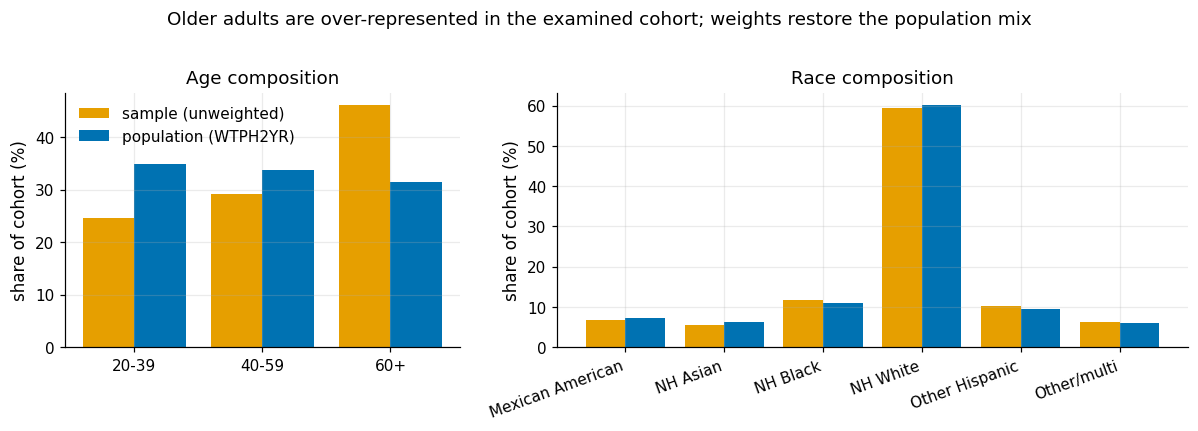

In [12]:
band_s = S.age_band(d["RIDAGEYR"]).to_numpy()
rep_rows = []
for dim, vals in [("age", band_s), ("race", d["race3"].to_numpy())]:
    for lev in pd.unique(vals):
        m = vals == lev
        rep_rows.append({"dimension": dim, "level": lev, "n": int(m.sum()), "sample_share": m.mean(),
                         "weighted_share": d.loc[m, WT].sum() / d[WT].sum()})
rep = pd.DataFrame(rep_rows).sort_values(["dimension", "level"]).reset_index(drop=True)
rep["diff_pp"] = 100 * (rep["sample_share"] - rep["weighted_share"])
print(rep.round(3).to_string(index=False))
deff = S.kish_deff(d[WT])
unw_prev = d["L_comb"].mean()
print(f"\nKish design effect of WTPH2YR: {deff:.2f} (effective n ≈ {len(d) / deff:,.0f}); "
      f"L_comb unweighted {pct(unw_prev)} vs weighted {pct(w_prev['est'])}")
RP = rep.set_index(["dimension", "level"])
close(RP.loc[("age", "60+"), "sample_share"], 0.462, 0.001, "60+ sample"); close(RP.loc[("age", "60+"), "weighted_share"], 0.314, 0.001, "60+ weighted")
close(RP.loc[("age", "20-39"), "sample_share"], 0.247, 0.001, "20-39 sample"); close(RP.loc[("age", "20-39"), "weighted_share"], 0.348, 0.001, "20-39 weighted")
close(deff, 1.55, 0.01, "Kish deff")

# Response rates are documented by NCHS, not derivable from public files (S2 provenance; NHANES 2021-2023
# overview brief, https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023).
RESPONSE = {"interview_unweighted": 0.346, "exam_unweighted": 0.257}
print(f"documented response rates: interview {pct(RESPONSE['interview_unweighted'])}, exam {pct(RESPONSE['exam_unweighted'])}")

merged = NIO.load_merged()
merged.attrs = {}
adults = merged[merged["RIDAGEYR"] >= C.ADULT_MIN_AGE].copy()
adults["self_dm"] = adults["DIQ010"].eq(1).astype(float).where(adults["DIQ010"].notna())
io_mask = adults["RIDSTATR"].eq(1).to_numpy()
a1c_mask = (adults["RIDSTATR"].eq(2) & adults["LBXGH"].notna()).to_numpy()
p_io = S.weighted_prop(adults, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=io_mask)
p_a1c = S.weighted_prop(adults, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=a1c_mask)
rd_sel = risk_difference(adults, "self_dm", a1c_mask, io_mask, weight=C.WEIGHT_INTERVIEW)
print(f"self-reported diabetes (WTINT2YR): interview-only adults {kg_text(p_io)}")
print(f"                                   adults with HbA1c   {kg_text(p_a1c)}")
print(f"difference with HbA1c - interview-only: {100 * rd_sel['est']:+.1f} pp ({100 * rd_sel['ci_low']:.1f}, {100 * rd_sel['ci_high']:.1f})")
close(p_io["est"], 0.088, 0.0015, "interview-only self-report"); close(p_a1c["est"], 0.117, 0.0015, "with-A1c self-report")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, dim in zip(axes, ["age", "race"]):
    rr = rep[rep["dimension"] == dim]
    x = np.arange(len(rr))
    ax.bar(x - 0.2, rr["sample_share"] * 100, 0.4, label="sample (unweighted)", color=plots.PALETTE[0])
    ax.bar(x + 0.2, rr["weighted_share"] * 100, 0.4, label="population (WTPH2YR)", color=plots.PALETTE[4])
    ax.set_xticks(x, rr["level"], rotation=0 if dim == "age" else 20, ha="center" if dim == "age" else "right")
    ax.set(ylabel="share of cohort (%)", title=f"{dim.capitalize()} composition")
axes[0].legend()
fig.suptitle("Older adults are over-represented in the examined cohort; weights restore the population mix", y=1.02)
fig.tight_layout()
plots.savefig(fig, "S5_representation",
              caption="Sample versus WTPH2YR-weighted composition of the 5,730-adult cohort by age band and race/ethnicity.")
plt.show()

rep.to_csv(OUT / "representation.csv", index=False)
RES["representation"] = {
    "shares": {f"{a}|{b}": v for (a, b), v in RP[["n", "sample_share", "weighted_share"]].to_dict("index").items()},
    "kish_deff": deff, "n_eff_kish": len(d) / deff, "L_comb_unweighted": unw_prev,
    "response_rates_documented": RESPONSE,
    "self_dm_interview_only": {k: p_io[k] for k in ("est", "kg_low", "kg_high", "n")},
    "self_dm_with_a1c": {k: p_a1c[k] for k in ("est", "kg_low", "kg_high", "n")},
    "selection_rd": {"est": rd_sel["est"], "ci_low": rd_sel["ci_low"], "ci_high": rd_sel["ci_high"]},
}
register("DR-S5-07", "representation",
         "Cohort over-represents older adults; exam participants report more diabetes than interview-only adults",
         "results/S5/representation.csv; figures/S5_representation.png",
         f"60+: sample {pct(RP.loc[('age', '60+'), 'sample_share'])} vs weighted {pct(RP.loc[('age', '60+'), 'weighted_share'])}; "
         f"Kish deff {deff:.2f}; self-report interview-only {pct(p_io['est'])} vs with HbA1c {pct(p_a1c['est'])}; response 34.6%/25.7%",
         "Descriptive population estimates use WTPH2YR with PSU jackknife; survey-weighted training only as ablation B6b; claims scoped to the examined population",
         "Treat the unweighted sample as the population; claim national representativeness of model metrics")

**So what.** Adults aged 60+ make up 46.2 % of the sample but 31.4 % of the weighted population (20–39: 24.7 %
vs 34.8 %); race shares differ by at most about one percentage point because this cycle no longer oversamples by
race. That age skew alone explains why the unweighted `L_comb` prevalence (16.9 %) exceeds the weighted 14.0 %.
Unequal weights cost precision (Kish design effect 1.55, effective n ≈ 3,700). With response rates of 34.6 %
(interview) and 25.7 % (exam), selection matters: interview-only adults report diabetes less often (8.8 %)
than adults with an HbA1c result (11.7 %). Weights correct for known covariates such as age, not for
health-related participation, so model metrics describe the examined population.

## 7 HbA1c missingness bias

**Why.** The cohort requires an HbA1c result. If HbA1c is missing more often in some groups and for health
reasons, the label is missing not at random. We compare missingness among examined adults by race, compare MEC- and phlebotomy-weighted prevalence (WTPH2YR already contains a blood-draw non-response
adjustment), and bound the `L_comb` prevalence without any assumption on the missing values (Manski bounds).
Self-report is observed for most adults without HbA1c, so the bounds are sharper than the naive width m.

In [13]:
# Missingness by race on all examined adults (the S3 definition); Manski bounds below on the cohort universe
# (examined, non-pregnant adults).
exa = adults[adults["RIDSTATR"].eq(2)].copy()
exa["a1c_missing"] = exa["LBXGH"].isna().astype(float)
exa["race3"] = exa["RIDRETH3"].map(RACE)
miss = (exa.groupby("race3")["a1c_missing"].agg(["mean", "size", "sum"])
        .rename(columns={"mean": "missing_share", "size": "examined", "sum": "missing"}))
miss["w_missing_share"] = [np.average(g["a1c_missing"], weights=g[C.WEIGHT_MEC]) for _, g in exa.groupby("race3")]
ex = exa[~exa["RIDEXPRG"].eq(1)].copy()
print(miss.round(3))
close(miss.loc["NH Black", "missing_share"], 0.093, 0.0015, "Black missing"); close(miss.loc["NH White", "missing_share"], 0.040, 0.0015, "White missing")

prev_mec = np.average(d["L_comb"], weights=d[C.WEIGHT_MEC])
print(f"\nL_comb prevalence: WTMEC2YR-weighted {pct(prev_mec)} vs WTPH2YR-weighted {pct(w_prev['est'])}")
close(prev_mec, 0.139, 0.0015, "MEC-weighted prevalence")

# Manski bounds on L_comb prevalence among examined adults (WTMEC2YR): missing HbA1c rows with self-reported
# diabetes are known positives; the rest could be anything.
ex["known_pos"] = (ex["LBXGH"].ge(C.HBA1C_DIABETES) | ex["DIQ010"].eq(1)).astype(float)
ex["unknown"] = (ex["LBXGH"].isna() & ~ex["DIQ010"].eq(1)).astype(float)
man = []
for g, gg in [("all", ex), *ex.groupby("race3")]:
    w = gg[C.WEIGHT_MEC].to_numpy()
    lo = np.average(gg["known_pos"], weights=w)
    unk = np.average(gg["unknown"], weights=w)
    obs = gg["LBXGH"].notna().to_numpy()
    man.append({"group": g, "observed_prev": np.average(gg.loc[obs, "known_pos"], weights=w[obs]),
                "lower": lo, "upper": lo + unk, "width": unk, "naive_width_m": np.average(gg["a1c_missing"], weights=w)})
manski = pd.DataFrame(man).set_index("group")
print("\nManski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)")
print(manski.round(3))
miss.to_csv(OUT / "a1c_missingness.csv")
manski.to_csv(OUT / "manski_bounds.csv")
RES["missingness"] = {"by_race": miss.to_dict("index"), "prev_mec": prev_mec, "prev_ph": w_prev["est"],
                      "manski": manski.to_dict("index")}
register("DR-S5-08", "missingness",
         "HbA1c is missing more often for NH Black adults; WTPH2YR adjustment changes prevalence by 0.1 pp",
         "results/S5/a1c_missingness.csv; results/S5/manski_bounds.csv",
         f"missing HbA1c: Black {pct(miss.loc['NH Black', 'missing_share'])} vs White {pct(miss.loc['NH White', 'missing_share'])}; "
         f"prevalence MEC {pct(prev_mec)} vs PH {pct(w_prev['est'])}; Manski width overall {manski.loc['all', 'width']:.3f}",
         "Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW sensitivity deferred to S9",
         "Impute HbA1c (would impute the label); ignore missingness")

                  missing_share  examined  missing  w_missing_share
race3                                                              
Mexican American          0.040       405     16.0            0.044
NH Asian                  0.060       335     20.0            0.058
NH Black                  0.093       753     70.0            0.089
NH White                  0.040      3569    142.0            0.040
Other Hispanic            0.042       614     26.0            0.044
Other/multi               0.059       388     23.0            0.073

L_comb prevalence: WTMEC2YR-weighted 13.9% vs WTPH2YR-weighted 14.0%

Manski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)
                  observed_prev  lower  upper  width  naive_width_m
group                                                              
all                       0.139  0.139  0.181  0.042          0.049
Mexican American          0.170  0.169  0.207  0.038          0.044
NH Asian                  0.114  0.1

**So what.** HbA1c is missing for 9.3 % of examined NH Black adults versus 4.0 % of NH White adults, so the
label is less often observed in one group. The phlebotomy weights already adjust for blood-draw non-response:
prevalence moves from 13.9 % (MEC weight) to 14.0 % (WTPH2YR). Without any assumption on the missing values the
overall `L_comb` prevalence among examined non-pregnant adults lies between 13.9 % and 18.1 % (width 0.042,
narrower than the naive 0.049 because missing-HbA1c adults who self-report diabetes are known positives); for
NH Black adults the bounds are 21.5–28.4 % (width 0.069) against 12.4–15.9 % for NH White adults. The cohort stays complete-case
with WTPH2YR; an inverse-probability-weighting sensitivity check is assigned to S9.

## 8 Decision gate L2 and target freeze

**Why.** Loop L2 (process doc §4) sends the project back to S1 if the label audit changes the question. Four
criteria decide whether `L_comb` can be frozen. They are evaluated **after** seeing the data (post-hoc), so they
are a documented judgement, not a pre-registered test. The freeze then fixes the target, the second primary
evaluation population E-SCREEN, the 3×3 label-matrix strata and the sensitivity labels SL1–SL7, written as
executable definitions in `governance/label_freeze.md` (all point to `src/labels.py`).

In [14]:
spec = NIO.load_spec()
TARGET_PARTS = ["LBXGH", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180", "LBXGLU"]
adm = spec[spec["var"].isin(TARGET_PARTS)].drop_duplicates("var").set_index("var")["admissible"].astype(str)
assert set(adm.index) == set(TARGET_PARTS), set(TARGET_PARTS) - set(adm.index)
c2_bad = adm[adm.str.upper().isin(["T1", "T2"])]
race_pos = d.groupby("race3")[["L_comb", "L_A1c"]].sum()
sl = L.sensitivity_labels(d)
c1 = {"self_missed": miss_self / n_comb, "a1c_missed": miss_a1c / n_comb, "kappa": unw["kappa"], "pa": unw["pa"], "na": unw["na"]}
gate = pd.DataFrame([
    {"criterion": "C1 descriptive evidence: each single instrument misses a material share of the union",
     "evidence": f"L_self misses {miss_self}/{n_comb} = {pct(c1['self_missed'])}; L_A1c misses {miss_a1c}/{n_comb} = {pct(c1['a1c_missed'])}; "
                 f"kappa {c1['kappa']:.2f}, PA {c1['pa']:.2f}, NA {c1['na']:.2f}",
     "verdict": "PASS (union justified; post-hoc judgement)"},
    {"criterion": "C2 no admissible feature is a component of the target",
     "evidence": f"variable_spec admissible flag of {', '.join(TARGET_PARTS)}: {sorted(set(adm.fillna('missing')))}",
     "verdict": "PASS" if c2_bad.empty else f"FAIL: {list(c2_bad.index)}"},
    {"criterion": "C3 >= 500 positives overall and >= 40 in the smallest reported group",
     "evidence": f"L_comb {n_comb}; smallest race group (L_comb) {race_pos['L_comb'].idxmin()} {int(race_pos['L_comb'].min())}; "
                 f"NH Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}, L_A1c {int(race_pos.loc['NH Asian', 'L_A1c'])}",
     "verdict": "PASS (NH Asian under L_A1c exactly at the line: descriptive only)"},
    {"criterion": "C4 borderline coding handled as sensitivity",
     "evidence": f"borderline positive (SL3): {int(sl['SL3'].sum())} positives vs {n_comb}",
     "verdict": "PASS (borderline negative + flagged; SL3 as sensitivity)"},
])
print(gate.to_string(index=False))
assert c2_bad.empty and n_comb >= 500 and race_pos["L_comb"].min() >= 40 and race_pos.loc["NH Asian", "L_A1c"] >= 40
assert int(sl["SL3"].sum()) == 1148
close(c1["self_missed"], 0.157, 0.001, "C1 self missed"); close(c1["a1c_missed"], 0.257, 0.001, "C1 A1c missed")
gate.to_csv(OUT / "l2_gate.csv", index=False)

                                                                           criterion                                                                                                      evidence                                                           verdict
C1 descriptive evidence: each single instrument misses a material share of the union                     L_self misses 152/971 = 15.7%; L_A1c misses 250/971 = 25.7%; kappa 0.70, PA 0.74, NA 0.96                        PASS (union justified; post-hoc judgement)
                               C2 no admissible feature is a component of the target variable_spec admissible flag of LBXGH, DIQ010, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180, LBXGLU: ['N']                                                              PASS
                C3 >= 500 positives overall and >= 40 in the smallest reported group                            L_comb 971; smallest race group (L_comb) NH Asian 50; NH Asian L_comb 50, L_A1c 40 PASS (NH Asian under L

**E-SCREEN, 3×3 strata and sensitivity labels.** The frozen definitions are computed once more from
`src/labels.py` and compared with the counts written into `governance/label_freeze.md`, so the document and
the code cannot drift apart.

3x3 evaluation strata: {'D_uncontrolled': 569, 'D_controlled': 250, 'Undiagnosed': 152, 'NonDiabetic': 4759}
E-SCREEN: {'n': 4911, 'positives': 152, 'negatives': 4759, 'borderline_in_escreen': 213, 'borderline_positive': 36}
label                                                    definition    n  positives  prev_unweighted   weight  w_prev  w_ci_low  w_ci_high
  SL1                                                    L_A1c only 5730        721            0.126  WTPH2YR   0.105     0.092      0.119
  SL2                                                   L_self only 5730        819            0.143  WTPH2YR   0.118     0.102      0.133
  SL3                                   borderline counted positive 5730       1148            0.200  WTPH2YR   0.167     0.149      0.184
  SL4 treatment-aware (A1c or treated self-report, DIQ070 universe) 5730        886            0.155  WTPH2YR   0.128     0.113      0.143
  SL5  NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample 2938        

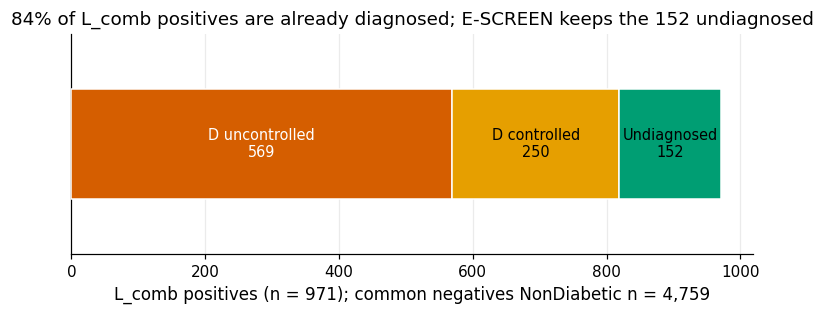

In [15]:
strata = L.strata_counts(d)
esc = d[d["in_escreen"] == 1]
esc_counts = {"n": len(esc), "positives": int(esc["y_escreen"].sum()), "negatives": int((esc["y_escreen"] == 0).sum()),
              "borderline_in_escreen": int(esc["borderline"].sum()),
              "borderline_positive": int(((esc["borderline"] == 1) & (esc["y_escreen"] == 1)).sum())}
print("3x3 evaluation strata:", strata)
print("E-SCREEN:", esc_counts)
assert strata == {"D_uncontrolled": 569, "D_controlled": 250, "Undiagnosed": 152, "NonDiabetic": 4759}
assert esc_counts["positives"] == 152 and esc_counts["borderline_positive"] == 36

fm = L.fasting_mask(d)
sl_rows = []
for col, desc, wcol in [("SL1", "L_A1c only", WT), ("SL2", "L_self only", WT), ("SL3", "borderline counted positive", WT),
                        ("SL4", "treatment-aware (A1c or treated self-report, DIQ070 universe)", WT),
                        ("SL5", "NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample", C.WEIGHT_FASTING)]:
    w = S.weighted_prop(d.assign(_y=sl[col]), "_y", weight=wcol)
    sl_rows.append({"label": col, "definition": desc, "n": int(sl[col].notna().sum()), "positives": int(sl[col].sum()),
                    "prev_unweighted": sl[col].mean(), "weight": wcol, "w_prev": w["est"], "w_ci_low": w["ci_low"], "w_ci_high": w["ci_high"]})
sl_tab = pd.DataFrame(sl_rows)
print(sl_tab.round(3).to_string(index=False))
univ = L.diq070_universe(d)
pills_by_status = d[d["DIQ070"].eq(1)].groupby(d["DIQ010"].map({1: "diagnosed", 2: "no (told prediabetes)", 3: "borderline"})).size()
print("DIQ070 = 1 by DIQ010:", pills_by_status.to_dict(), f"; DIQ070 universe n = {int(univ.sum())}")
SLT = sl_tab.set_index("label")
assert SLT["positives"].tolist() == [721, 819, 1148, 886, int(SLT.loc["SL5", "positives"])]
assert pills_by_status.to_dict() == {"borderline": 44, "diagnosed": 592, "no (told prediabetes)": 41}
close(SLT.loc["SL5", "w_prev"], 0.158, 0.006, "SL5 vs NCHS DB516 15.8%")

freeze_path = C.GOVERNANCE_DIR / "label_freeze.md"
freeze_text = freeze_path.read_text(encoding="utf-8")
frozen = json.loads(freeze_text.split("```json")[1].split("```")[0])
computed = {"N": len(d), "L_comb": n_comb, "L_self": int(d["L_self"].sum()), "L_A1c": int(d["L_A1c"].sum()),
            "strata_3x3": strata, "escreen_positives": esc_counts["positives"], "escreen_negatives": esc_counts["negatives"],
            "escreen_borderline_positive": esc_counts["borderline_positive"],
            "SL_positives": {k: int(v) for k, v in SLT["positives"].items()}, "SL5_n": int(SLT.loc["SL5", "n"])}
assert frozen == computed, {k: (frozen.get(k), v) for k, v in computed.items() if frozen.get(k) != v}
freeze_sha = hashlib.sha256(freeze_path.read_bytes()).hexdigest()
print(f"label_freeze.md counts match the code; SHA-256 {freeze_sha[:16]}…")

fig, ax = plt.subplots(figsize=(8, 2.6))
cols = [plots.PALETTE[5], plots.PALETTE[0], plots.PALETTE[2]]
left = 0
for k, col in zip(L.POSITIVE_STRATA, cols):
    ax.barh(0, strata[k], left=left, height=0.5, color=col, edgecolor="white", zorder=3)
    ax.text(left + strata[k] / 2, 0, f"{k.replace('_', ' ')}\n{strata[k]}", ha="center", va="center", fontsize=9.5,
            color="white" if k == "D_uncontrolled" else "black", zorder=4)
    left += strata[k]
ax.set_yticks([])
ax.grid(axis="y", visible=False)
known = strata["D_uncontrolled"] + strata["D_controlled"]
ax.set(xlabel=f"L_comb positives (n = {n_comb}); common negatives NonDiabetic n = {strata['NonDiabetic']:,}", ylim=(-0.5, 0.5),
       title=f"{pct(known / n_comb, 0)} of L_comb positives are already diagnosed; E-SCREEN keeps the {strata['Undiagnosed']} undiagnosed")
plots.savefig(fig, "S5_label_strata", caption="Composition of the 971 L_comb positives by self-report and HbA1c; "
              "D_uncontrolled 569, D_controlled 250, Undiagnosed 152 (= E-SCREEN positives).")
plt.show()

sl_tab.to_csv(OUT / "sensitivity_labels.csv", index=False)
RES["freeze"] = {"target": "L_comb = (DIQ010 == 1) | (LBXGH >= 6.5)", "N": len(d), "gate": gate.set_index("criterion")["verdict"].to_dict(),
                 "gate_posthoc": True, "strata_3x3": strata, "escreen": esc_counts,
                 "sensitivity_labels": sl_tab.set_index("label")[["n", "positives", "prev_unweighted", "w_prev", "weight"]].to_dict("index"),
                 "known_dx_share_of_positives": strata["D_uncontrolled"] / n_comb + strata["D_controlled"] / n_comb,
                 "label_freeze_sha256": freeze_sha}
register("DR-S5-01", "target_freeze",
         "L2 gate C1-C4 passes (post-hoc); the union label is the least biased single target",
         "results/S5/l2_gate.csv; governance/label_freeze.md",
         f"L_comb {n_comb} positives ({pct(n_comb / len(d))}; weighted {pct(w_prev['est'])}); C1 15.7%/25.7% missed by single labels; "
         f"C3 Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}",
         "Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2",
         "Freeze L_self (misses 152 undiagnosed); freeze L_A1c (misses 250 controlled); borderline positive (SL3, kept as sensitivity)",
         loop_ref="L2", check_note="Gate recomputed in section 5.8; post-hoc nature stated")
register("DR-S5-09", "evaluation_population",
         "84% of L_comb positives are already diagnosed, so E-ALL measures recognition of known disease",
         "governance/label_freeze.md; figures/S5_label_strata.png",
         f"E-SCREEN: {esc_counts['n']} adults, {esc_counts['positives']} positives vs {esc_counts['negatives']} negatives; "
         f"borderline kept with {esc_counts['borderline_positive']} positive; 3x3 strata 569/250/152/4759",
         "E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation population next to E-ALL; 3x3 label matrix (SL6) evaluated in S8 at specificity 0.80",
         "Evaluate on E-ALL only; train on E-SCREEN only (152 events too few)", loop_ref="L2")
register("DR-S5-10", "sensitivity_labels",
         "Label definition is a researcher degree of freedom; robustness needs pre-specified alternatives",
         "results/S5/sensitivity_labels.csv; governance/label_freeze.md",
         "SL1 721, SL2 819, SL3 1,148, SL4 886, SL5 " + f"{int(SLT.loc['SL5', 'positives'])}/{int(SLT.loc['SL5', 'n'])} (weighted {pct(SLT.loc['SL5', 'w_prev'])})",
         "Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses only the DIQ070 universe and excludes pills of non-diagnosed respondents; S9 reports results under SL1-SL5, S8 runs SL6, S9 runs SL7",
         "Ad-hoc relabelling after seeing model results; DIQ070 pills as diabetes for all respondents (would count metformin for prediabetes)")

**So what.** All four gate criteria pass; we state explicitly that this is a post-hoc judgement made after
seeing the data. Each single instrument misses a material share of the union (15.7 % and 25.7 %), no admissible
feature is part of the target, every race group has at least 40 positives (NH Asian: 50 under `L_comb`, exactly
40 under `L_A1c`, so Asian results stay descriptive), and the borderline coding is handled by SL3 (1,148
positives). **`L_comb` is frozen** (`target-freeze`).

The 971 positives split into 569 uncontrolled and 250 controlled known diabetics and 152 undiagnosed adults:
84 % of all positives are already diagnosed, so an AUC on E-ALL largely measures recognition of known disease.
E-SCREEN (adults not reporting diabetes; 152 HbA1c-positive vs 4,759 negatives, borderline respondents kept
and flagged, 36 of them positive) is therefore a co-primary evaluation population, and S8 evaluates every
training label on each 3×3 column against the common 4,759 negatives. The sensitivity labels behave as
expected: the treatment-aware SL4 (886) sits between `L_A1c` and `L_comb`, and the NCHS definition SL5 on the
fasting subsample reproduces the published 15.8 % prevalence closely, which anchors our label pipeline to an
external benchmark.

**Status of the S5 hypotheses.** Three entries of `governance/hypotheses.md` are checked in this section. All
three were written after the data had been analysed (`analysis_seen` / `descriptive_seen`), so a "supported"
verdict here confirms a reproduced description; it is not confirmatory evidence.

In [16]:
from statsmodels.stats.proportion import confint_proportions_2indep

ka, na_ = int(bmi_dm.loc["NH Asian", "bmi_lt25"]), int(bmi_dm.loc["NH Asian", "diabetics_with_bmi"])
kw, nw = int(bmi_dm.loc["NH White", "bmi_lt25"]), int(bmi_dm.loc["NH White", "diabetics_with_bmi"])
h4a_lo, h4a_hi = confint_proportions_2indep(ka, na_, kw, nw, method="newcomb", compare="diff")
h4a = ka / na_ - kw / nw
rd_bmi = risk_difference(d.assign(bmi_lt25=(d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna())), "bmi_lt25",
                         ((d["RIDRETH3"] == 6) & (d["L_comb"] == 1)).to_numpy(), ((d["RIDRETH3"] == 3) & (d["L_comb"] == 1)).to_numpy())
g_as, g_wh = RO.loc[("NH Asian", "WHtR − BMI (paired)")], RO.loc[("NH White", "WHtR − BMI (paired)")]
rd_un = RD.loc["uninsured - insured"]
hyp = pd.DataFrame([
    {"hyp_id": "H1a", "estimate": f"RD uninsured - insured {rd_un['rd_pp']:+.1f} pp ({rd_un['ci_low_pp']:.1f}, {rd_un['ci_high_pp']:.1f})",
     "rule": "lower CI bound > 0", "verdict": "supported" if rd_un["ci_low_pp"] > 0 else "inconclusive",
     "note": "uninsured share exploratory (KG width >= 0.30)"},
    {"hyp_id": "H4a", "estimate": f"BMI<25 among diabetics, Asian - White {100 * h4a:+.1f} pp (Newcombe {100 * h4a_lo:.1f}, {100 * h4a_hi:.1f}); "
                                  f"weighted {100 * rd_bmi['est']:+.1f} pp (JK {100 * rd_bmi['ci_low']:.1f}, {100 * rd_bmi['ci_high']:.1f})",
     "rule": "difference >= 20 pp with CI above 20 pp",
     "verdict": "supported" if h4a_lo >= 0.20 else ("inconclusive" if h4a >= 0.20 else "refuted"),
     "note": "47 Asian diabetics with BMI: exploratory"},
    {"hyp_id": "H4b", "estimate": f"WHtR - BMI gain Asian {g_as['auc']:+.3f} ({g_as['ci_low']:.3f}, {g_as['ci_high']:.3f}) vs "
                                  f"White {g_wh['auc']:+.3f} ({g_wh['ci_low']:.3f}, {g_wh['ci_high']:.3f}); difference CI "
                                  f"({gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f})",
     "rule": "Asian gain larger and CIs not fully overlapping",
     "verdict": "supported" if (g_as["auc"] > g_wh["auc"] and g_as["ci_low"] > g_wh["ci_low"] and gain_diff.quantile(.025) > 0) else "inconclusive",
     "note": "descriptive_seen; confirmatory test of the WHtR arm is P14 in S8"},
])
print(hyp.to_string(index=False))
assert hyp["verdict"].tolist() == ["supported", "supported", "supported"]
hyp.to_csv(OUT / "hypothesis_checks.csv", index=False)
RES["hypotheses"] = hyp.set_index("hyp_id").to_dict("index")
for r in REG:   # link register rows to the hypotheses they inform
    r["hyp_id"] = {"DR-S5-05": "H1a", "DR-S5-06": "H4a; H4b", "DR-S5-09": "H2c; H3"}.get(r["dr_id"], r["hyp_id"])

# prior_exposure of every hypothesis, read from the locked governance/hypotheses.md
_rows = [ln.split("|") for ln in (C.GOVERNANCE_DIR / "hypotheses.md").read_text(encoding="utf-8").splitlines()
         if ln.startswith("| H") and not ln.startswith("| hyp_id")]
prior = {r[1].strip(): r[9].strip() for r in _rows if len(r) > 10}
print("prior_exposure:", prior)
genuine = sorted(h for h, p in prior.items() if p == "none")
print("genuinely pre-registered (prior_exposure = none):", genuine)
assert {"H2b", "H2c", "H3"} <= set(genuine) and prior.get("H2a") == "analysis_seen"

hyp_id                                                                                                   estimate                                            rule   verdict                                                             note
   H1a                                                                RD uninsured - insured +23.2 pp (6.2, 40.1)                              lower CI bound > 0 supported                   uninsured share exploratory (KG width >= 0.30)
   H4a    BMI<25 among diabetics, Asian - White +43.9 pp (Newcombe 29.8, 57.7); weighted +43.4 pp (JK 23.2, 63.5)         difference >= 20 pp with CI above 20 pp supported                         47 Asian diabetics with BMI: exploratory
   H4b WHtR - BMI gain Asian +0.137 (0.097, 0.184) vs White +0.049 (0.038, 0.058); difference CI (+0.045, +0.138) Asian gain larger and CIs not fully overlapping supported descriptive_seen; confirmatory test of the WHtR arm is P14 in S8
prior_exposure: {'H1a': 'analysis_seen', 'H1b': 'ana

**So what.** H1a (uninsured adults more often undiagnosed), H4a (BMI < 25 far more common among Asian
diabetics) and H4b (larger WHtR gain in Asian adults) are reproduced with intervals that satisfy their
pre-stated rules, with the caveats printed above. Because the hypotheses were written after seeing these data,
they are recorded as *supported (analysis_seen)*. The genuinely pre-registered tests (`prior_exposure = none`)
are H2b, H2c and H3 in S7/S8; H2a (leakage gate) is `analysis_seen` and the WHtR arm P14 is `descriptive_seen`.

In [17]:
reg_df = pd.DataFrame(REG).sort_values("dr_id").reset_index(drop=True)
reg_path = C.GOVERNANCE_DIR / "register" / "S5.csv"
reg_path.parent.mkdir(parents=True, exist_ok=True)
reg_df.to_csv(reg_path, index=False, lineterminator="\n")
R.save_section("S5", RES)
print(f"{len(reg_df)} register rows -> {reg_path.relative_to(C.ROOT).as_posix()}; results -> results/metrics_S5.json")
print(reg_df[["dr_id", "type", "decision"]].to_string(index=False))

10 register rows -> governance/register/S5.csv; results -> results/metrics_S5.json
   dr_id                  type                                                                                                                                                                                                decision
DR-S5-01         target_freeze                                                                           Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2
DR-S5-02           label_audit                                                                                Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1
DR-S5-03            label_bias                                                                        Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diag